# Brain MRI classification test report

This notebook evaluates one trained three-class brain MRI model on the held-out `test` split produced by `data_processing/data_analysis.ipynb`. It reports per-class precision, recall, F1 and support, macro/weighted metrics, balanced accuracy, ROC-AUC when defined, timing, a normalized confusion matrix, and a CSV of per-image predictions.

Run the preprocessing notebook first. Set `CHECKPOINT_PATH` and `ARCHITECTURE` below to the checkpoint you want to evaluate. The report uses the saved training normalization statistics and the non-augmented test transform. Use the test split only for final evaluation, not model or hyperparameter selection.

The source folders are named `1`, `2`, and `3`. `CLASS_NAME_MAP` below uses neutral names by default; change the values only after confirming the class-to-folder mapping from the dataset documentation.

In [120]:
from pathlib import Path
import csv
import json
import time
REPORT_STARTED_AT = time.perf_counter()

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torch.utils.data import DataLoader

from data_processing.data_loaders import BrainMRIDataLoader
import model.model as model_architectures

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "processed_scan_images_mri").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

ARCHITECTURE = "EfficientNetB0"  # ResNet18/34/50/101/152, SqueezeNet, EfficientNetB0
root = "saved/training/brain-tumor-EfficientNetB0/1120_205812/model_best.pth"
CHECKPOINT_PATH = PROJECT_ROOT / root
TEST_DATA_DIR = PROJECT_ROOT / "processed_scan_images_mri"
BATCH_SIZE = 32
NUM_WORKERS = 0
CLASS_NAME_MAP = {
    "1": "Meningioma",
    "2": "Glioma",
    "3": "Pituitary",
}
REPORT_DIR = PROJECT_ROOT / "reports" / CHECKPOINT_PATH.parent.name

if ARCHITECTURE not in model_architectures.__all__:
    raise ValueError(f"Unsupported model architecture: {ARCHITECTURE}")
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}. Update CHECKPOINT_PATH to your trained model."
    )
if not (TEST_DATA_DIR / "test").is_dir():
    raise FileNotFoundError(
        f"Test split not found: {TEST_DATA_DIR / 'test'}. Run the preprocessing notebook first."
    )

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Architecture: {ARCHITECTURE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Device: {DEVICE}")

Architecture: EfficientNetB0
Checkpoint: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/saved/training/brain-tumor-EfficientNetB0/1120_205812/model_best.pth
Device: mps


In [121]:
test_loader_wrapper = BrainMRIDataLoader(
    mode="test",
    data_dir=str(TEST_DATA_DIR),
    batch_size=BATCH_SIZE,
    shuffle=False,
    validation_split=0.0,
    num_workers=NUM_WORKERS,
    weighted_sampling=False,
)
test_dataset = test_loader_wrapper.dataset
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
class_names = [CLASS_NAME_MAP.get(folder, folder) for folder in test_dataset.classes]
num_classes = len(test_dataset.classes)
if num_classes != 3:
    raise ValueError(f"Expected 3 test classes, found {test_dataset.classes}")

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
model = getattr(model_architectures, ARCHITECTURE)(
    num_classes=num_classes,
    use_pretrained=False,
)
state_dict = checkpoint.get("state_dict", checkpoint)
if any(key.startswith("module.") for key in state_dict):
    state_dict = {key.removeprefix("module."): value for key, value in state_dict.items()}
model.load_state_dict(state_dict)
model = model.to(DEVICE)
model.eval()

print(f"Class folders: {test_dataset.classes}")
print(f"Class names used in report: {class_names}")
print(f"Test images: {len(test_dataset)}")
print("Test images per class:")
for class_index, class_name in enumerate(class_names):
    count = sum(target == class_index for target in test_dataset.targets)
    print(f"  {class_name}: {count}")

Class folders: ['1', '2', '3']
Class names used in report: ['Meningioma', 'Glioma', 'Pituitary']
Test images: 460
Test images per class:
  Meningioma: 107
  Glioma: 214
  Pituitary: 139


In [122]:
import json
from pathlib import Path

import torch

checkpoint_path = Path(
    root
)
metrics_path = checkpoint_path.parent / "metrics.json"

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
best_epoch = checkpoint["epoch"]

run_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
epoch_metrics = next(
    (item for item in run_metrics["epoch_metrics"] if item["epoch"] == best_epoch),
    None,
)

if epoch_metrics is None:
    raise ValueError(f"No metrics found for checkpoint epoch {best_epoch}")

print(f"Best checkpoint: {checkpoint_path}")
print(f"Epoch: {best_epoch}")
print(f"Training loss: {epoch_metrics['loss']:.4f}")
print(f"Training accuracy: {epoch_metrics['accuracy']:.2%}")
print(f"Validation loss: {epoch_metrics['val_loss']:.4f}")
print(f"Validation accuracy: {epoch_metrics['val_accuracy']:.2%}")

Best checkpoint: saved/training/brain-tumor-EfficientNetB0/1120_205812/model_best.pth
Epoch: 8
Training loss: 0.0398
Training accuracy: 98.65%
Validation loss: 0.0352
Validation accuracy: 98.49%


In [123]:
def synchronize_device(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


all_labels = []
all_predictions = []
all_probabilities = []
total_loss = 0.0
criterion = torch.nn.CrossEntropyLoss(reduction="sum")
test_started = time.perf_counter()
inference_seconds = 0.0

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        synchronize_device(DEVICE)
        inference_started = time.perf_counter()
        logits = model(images)
        synchronize_device(DEVICE)
        inference_seconds += time.perf_counter() - inference_started

        total_loss += criterion(logits, labels).item()
        probabilities = torch.softmax(logits, dim=1)
        all_labels.append(labels.cpu().numpy())
        all_predictions.append(logits.argmax(dim=1).cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

synchronize_device(DEVICE)
test_seconds = time.perf_counter() - test_started
y_true = np.concatenate(all_labels)
y_pred = np.concatenate(all_predictions)
y_prob = np.concatenate(all_probabilities)
test_loss = total_loss / len(y_true)
inference_ms_per_image = inference_seconds * 1000 / len(y_true)

print(f"Evaluated images: {len(y_true)}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Cumulative test evaluation time (includes data loading/metrics): {test_seconds:.2f} s")
print(f"Cumulative model forward-pass time: {inference_seconds:.2f} s")
print(f"Mean forward-pass time: {inference_ms_per_image:.2f} ms/image")

Evaluated images: 460
Test loss: 0.0593
Test accuracy: 0.9804
Cumulative test evaluation time (includes data loading/metrics): 1.81 s
Cumulative model forward-pass time: 1.06 s
Mean forward-pass time: 2.31 ms/image


In [124]:
class_indices = np.arange(num_classes)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=class_indices,
    zero_division=0,
)
report_text = classification_report(
    y_true,
    y_pred,
    labels=class_indices,
    target_names=class_names,
    zero_division=0,
)
report = classification_report(
    y_true,
    y_pred,
    labels=class_indices,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
confusion = confusion_matrix(y_true, y_pred, labels=class_indices)
confusion_normalized = confusion.astype(np.float64) / np.maximum(
    confusion.sum(axis=1, keepdims=True), 1
)

try:
    macro_auc = roc_auc_score(
        y_true,
        y_prob,
        labels=class_indices,
        multi_class="ovr",
        average="macro",
    )
except ValueError as error:
    macro_auc = None
    print(f"Macro ROC-AUC is undefined for this test split: {error}")

summary = {
    "architecture": ARCHITECTURE,
    "checkpoint": str(CHECKPOINT_PATH),
    "test_images": int(len(y_true)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "macro_precision": float(np.mean(precision)),
    "macro_recall": float(np.mean(recall)),
    "macro_f1": float(np.mean(f1)),
"weighted_precision": float(report["weighted avg"]["precision"]),
"weighted_recall": float(report["weighted avg"]["recall"]),
"weighted_f1": float(report["weighted avg"]["f1-score"]),
    "macro_roc_auc_ovr": None if macro_auc is None else float(macro_auc),
    "test_seconds": float(test_seconds),
    "inference_seconds": float(inference_seconds),
    "inference_ms_per_image": float(inference_ms_per_image),
}

print(report_text)
print("\nRequested overall test metrics:")
print(f"Overall Accuracy      : {summary['accuracy'] * 100:.2f}%")
print(f"Macro Precision       : {summary['macro_precision'] * 100:.2f}%")
print(f"Macro Recall          : {summary['macro_recall'] * 100:.2f}%")
print(f"Macro F1 - Score      : {summary['macro_f1'] * 100:.2f}%")
print(f"Weighted Precision    : {summary['weighted_precision'] * 100:.2f}%")
print(f"Weighted Recall       : {summary['weighted_recall'] * 100:.2f}%")
print(f"Weighted F1 - Score   : {summary['weighted_f1'] * 100:.2f}%")
if summary['macro_roc_auc_ovr'] is None:
    print("Macro AUC - ROC       : undefined for this test split")
else:
    print(f"Macro AUC - ROC       : {summary['macro_roc_auc_ovr'] * 100:.2f}%")
print(f"Cumulative Inference  : {summary['inference_seconds']:.2f} s total")
print(f"Mean Inference Time   : {summary['inference_ms_per_image']:.2f} ms/image")
print(f"Images Evaluated      : {summary['test_images']}")

              precision    recall  f1-score   support

  Meningioma       0.92      1.00      0.96       107
      Glioma       1.00      0.99      1.00       214
   Pituitary       1.00      0.95      0.97       139

    accuracy                           0.98       460
   macro avg       0.97      0.98      0.98       460
weighted avg       0.98      0.98      0.98       460


Requested overall test metrics:
Overall Accuracy      : 98.04%
Macro Precision       : 97.41%
Macro Recall          : 98.01%
Macro F1 - Score      : 97.64%
Weighted Precision    : 98.20%
Weighted Recall       : 98.04%
Weighted F1 - Score   : 98.06%
Macro AUC - ROC       : 99.93%
Cumulative Inference  : 1.06 s total
Mean Inference Time   : 2.31 ms/image
Images Evaluated      : 460


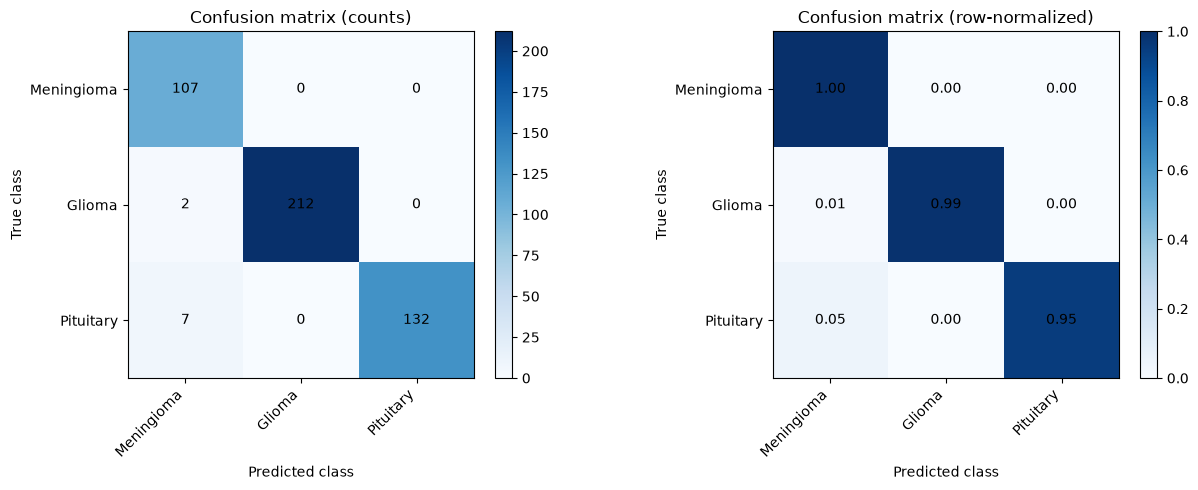

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
image = axes[0].imshow(confusion, interpolation="nearest", cmap="Blues")
axes[0].figure.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)
axes[0].set_xticks(np.arange(num_classes), labels=class_names, rotation=45, ha="right")
axes[0].set_yticks(np.arange(num_classes), labels=class_names)
for row in range(num_classes):
    for column in range(num_classes):
        axes[0].text(column, row, str(confusion[row, column]), ha="center", va="center")
axes[0].set_title("Confusion matrix (counts)")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")

image = axes[1].imshow(confusion_normalized, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
axes[1].figure.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set_xticks(np.arange(num_classes), labels=class_names, rotation=45, ha="right")
axes[1].set_yticks(np.arange(num_classes), labels=class_names)
for row in range(num_classes):
    for column in range(num_classes):
        axes[1].text(column, row, f"{confusion_normalized[row, column]:.2f}", ha="center", va="center")
axes[1].set_title("Confusion matrix (row-normalized)")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
fig.tight_layout()
plt.show()

In [126]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORT_DIR / "classification_report.csv"
with report_path.open("w", newline="", encoding="utf-8") as report_file:
    writer = csv.writer(report_file)
    writer.writerow(["class_or_average", "precision", "recall", "f1_score", "support"])
    for name, metrics in report.items():
        if isinstance(metrics, dict):
            writer.writerow([
                name,
                metrics.get("precision", ""),
                metrics.get("recall", ""),
                metrics.get("f1-score", ""),
                metrics.get("support", ""),
            ])

confusion_path = REPORT_DIR / "confusion_matrix.csv"
with confusion_path.open("w", newline="", encoding="utf-8") as confusion_file:
    writer = csv.writer(confusion_file)
    writer.writerow(["true_class/predicted_class", *class_names])
    for name, row in zip(class_names, confusion):
        writer.writerow([name, *row.tolist()])

prediction_rows = []
for image_path, true_index, predicted_index, probabilities in zip(
    test_dataset.imgs,
    y_true,
    y_pred,
    y_prob,
):
    path, _ = image_path
    prediction_rows.append({
        "image_path": str(Path(path).relative_to(PROJECT_ROOT)),
        "true_class": class_names[int(true_index)],
        "predicted_class": class_names[int(predicted_index)],
        "correct": bool(true_index == predicted_index),
        **{
            f"probability_{class_names[class_index]}": float(probabilities[class_index])
            for class_index in class_indices
        },
    })
predictions_path = REPORT_DIR / "predictions.csv"
with predictions_path.open("w", newline="", encoding="utf-8") as predictions_file:
    writer = csv.DictWriter(predictions_file, fieldnames=prediction_rows[0].keys())
    writer.writeheader()
    writer.writerows(prediction_rows)

fig.savefig(REPORT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.close(fig)

summary["run_elapsed_seconds"] = time.perf_counter() - REPORT_STARTED_AT
summary_path = REPORT_DIR / "summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print(f"Cumulative report run time: {summary['run_elapsed_seconds']:.2f} s")
print(f"Saved classification metrics: {report_path}")
print(f"Saved summary: {summary_path}")
print(f"Saved confusion matrix: {confusion_path}")
print(f"Saved per-image predictions: {predictions_path}")
print(f"Saved confusion matrix plot: {REPORT_DIR / 'confusion_matrix.png'}")

Cumulative report run time: 5.75 s
Saved classification metrics: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/reports/1120_205812/classification_report.csv
Saved summary: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/reports/1120_205812/summary.json
Saved confusion matrix: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/reports/1120_205812/confusion_matrix.csv
Saved per-image predictions: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/reports/1120_205812/predictions.csv
Saved confusion matrix plot: /Users/Oshadi/MSc/7004ENG_Individual_Project/OVST/Sample_Projects/Brain-scan/reports/1120_205812/confusion_matrix.png
